# Business problem

Over the last month:
- marketing spending increased by 65%;
- landing page visits increased by 60%;
- registrations increased by 55%;
- the number of new paying users increased by only 2%.

We need to understand why growth in acquisition is not leading to a comparable increase in sales and identify opportunities to improve marketing efficiency.

The indicators above define the initial business context. The rest of the analysis should not be predetermined.


## Research plan

Initial plan.

Problem: there is no growth in paying users despite marketing spending.

1. **Check the facts**
   - Growth in marketing spend
   - Growth in landing page visits
   - Growth in new users
   - Number of paying users

2. **Check acquisition channels** to test my first idea and compare differences between channels
   - Number of users who made a payment; successful payments
   - CAC
   - Conversion from registration to payment

After that, the plan will be adjusted **based on the situation**.

In [ ]:
from pathlib import Path
import os
import math

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import plotly.express as px
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

BASE_DIR = Path.cwd().parent
load_dotenv(BASE_DIR / ".env")

engine = create_engine(os.getenv("DATABASE_URL"))

IMG_DIR = Path("../img")
IMG_DIR.mkdir(parents=True, exist_ok=True)

### Fact check

The facts provided were confirmed.

C:\Temp\ipykernel_2176\608627520.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


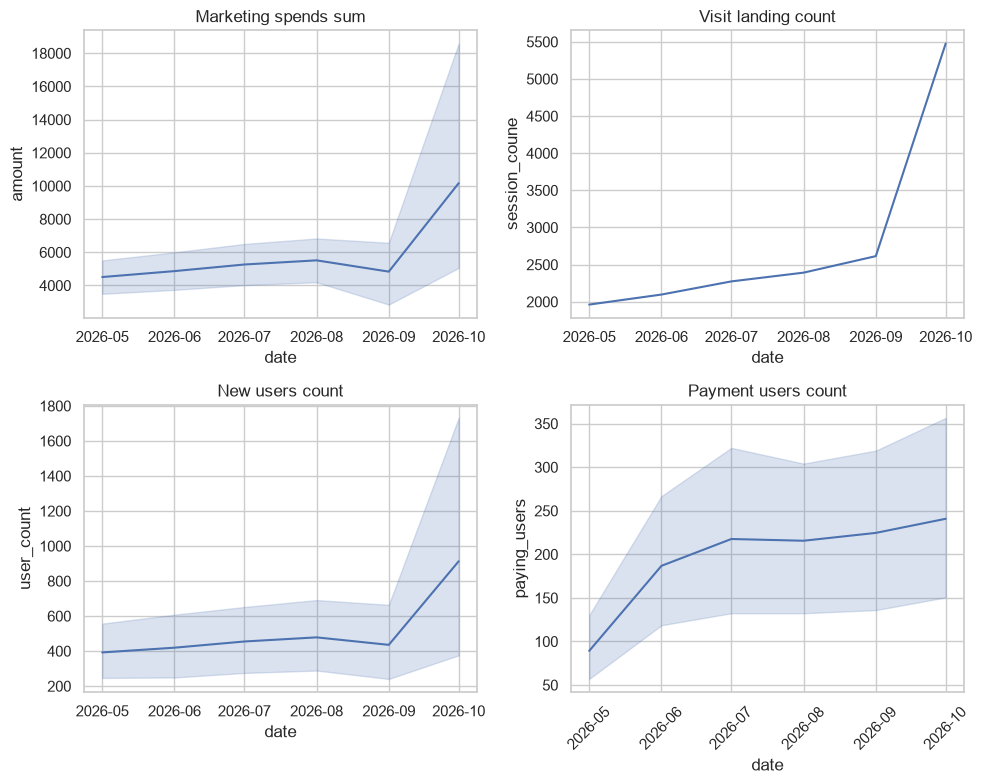

In [261]:
df_marketing_spend_by_channel = pd.read_sql(text("""
SELECT
    DATE_TRUNC('month', spend_date)::DATE as date,
    channel,
    SUM(COALESCE(spend_amount,0)) as amount
FROM marketing_spend m
GROUP BY 1,2
"""), engine)
df_marketing_spend_by_channel['date'] = pd.to_datetime(df_marketing_spend_by_channel['date'])
df_visit_landing = pd.read_sql(text("""
SELECT
    date_trunc('month', session_start) as date,
    COUNT(session_id) as session_coune
FROM web_sessions
GROUP BY 1
ORDER BY 1
"""), engine)
df_new_users = pd.read_sql(text("""
SELECT
    date_trunc('month', created_at) as date,
    LOWER(acquisition_channel) as channel,
    COUNT(DISTINCT user_id) as user_count
FROM users
GROUP BY 1,2
ORDER BY 1,2
"""), engine)
df_payment_users_by_channel = pd.read_sql(text("""
WITH channels AS (
    SELECT DISTINCT
        LOWER(u.acquisition_channel) AS channel,
        u.user_id
    FROM users u
)

SELECT
    date_trunc('month', p.payment_time) AS date,
    c.channel,
    COUNT(DISTINCT p.user_id) AS paying_users
FROM channels c
LEFT JOIN payments p
    ON p.user_id = c.user_id
   AND p.payment_status = 'succeeded'
GROUP BY 1, c.channel
ORDER BY 1,paying_users DESC;
"""), engine)

fig, ax = plt.subplots(2,2,figsize=(10,8))

sns.set_style('darkgrid')

sns.lineplot(data=df_marketing_spend_by_channel,x='date',y='amount', ax=ax[0,0])
ax[0,0].set_title("Marketing spends sum")
sns.lineplot(data=df_visit_landing,x='date',y='session_coune', ax=ax[0,1])
ax[0,1].set_title("Visit landing count")
sns.lineplot(data=df_new_users,x='date',y='user_count', ax=ax[1,0])
ax[1,0].set_title("New users count")
sns.lineplot(data=df_payment_users_by_channel,x='date',y='paying_users', ax=ax[1,1])
ax[1,1].set_title("Payment users count")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

fig.savefig(
    IMG_DIR / "check_facts.png",
    dpi=150,
    bbox_inches="tight"
)

fig.show()

### Checking acquisition channels

During the analysis, the following was found:

- users from the social broad channel never paid for a subscription. As a result:
  - CAC is undefined
  - purchase conversion is 0
  - number of paying users is 0

C:\Temp\ipykernel_2176\2580263256.py:115: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


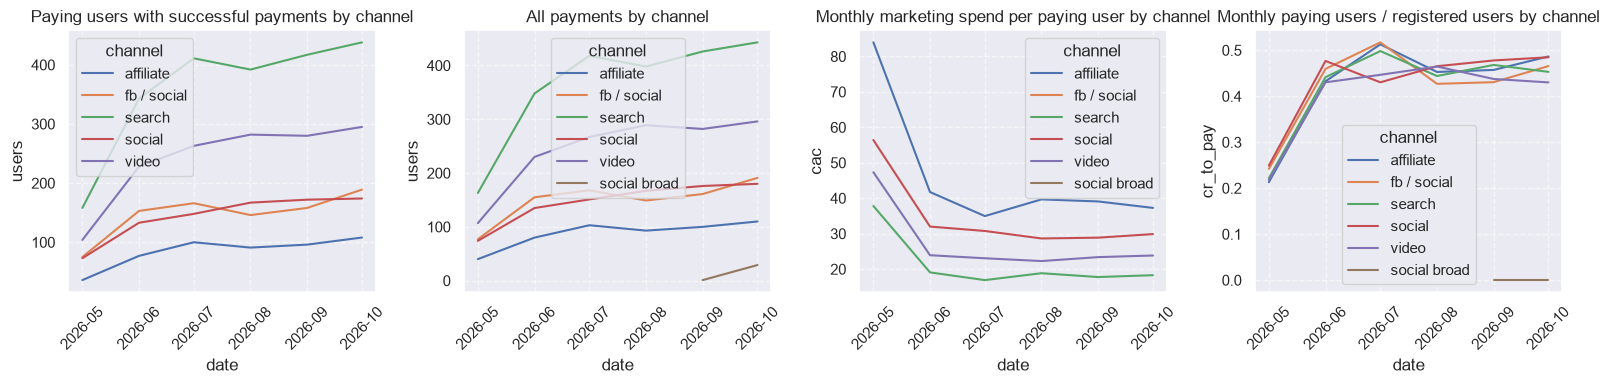

In [262]:
df_pay_users_succeeded = pd.read_sql(text("""
SELECT
    date_trunc('month', p.payment_time) as date,
    LOWER(u.acquisition_channel) as channel,
    COUNT(DISTINCT p.user_id) as users
FROM payments p
LEFT JOIN users u ON u.user_id = p.user_id
WHERE payment_time < '2026-11-01' AND payment_status = 'succeeded'
GROUP BY 1,2
ORDER BY 1,2
"""), engine)
df_pay_users = pd.read_sql(text("""
SELECT
    date_trunc('month', p.payment_time) as date,
    LOWER(u.acquisition_channel) as channel,
    COUNT(DISTINCT p.user_id) as users
FROM payments p
LEFT JOIN users u ON u.user_id = p.user_id
WHERE payment_time < '2026-11-01'
GROUP BY 1,2
ORDER BY 1,2
"""), engine)
df_CAC = pd.read_sql(text("""
WITH mark_spends_by_month AS (
    SELECT
        DATE_TRUNC('month', spend_date) AS date,
        LOWER(channel) AS channel,
        SUM(COALESCE(spend_amount, 0)) AS amount
    FROM marketing_spend
    GROUP BY 1, 2
),
users_count AS (
    SELECT
        DATE_TRUNC('month', p.payment_time) AS date,
        LOWER(u.acquisition_channel) AS channel,
        COUNT(DISTINCT p.user_id) AS users
    FROM payments p
    JOIN users u
        ON u.user_id = p.user_id
    WHERE p.payment_time < '2026-11-01'
      AND p.payment_status = 'succeeded'
    GROUP BY 1, 2
)
SELECT
    COALESCE(m.date, uc.date)::date AS date,
    COALESCE(m.channel, uc.channel) AS channel,
    COALESCE(m.amount, 0) AS marketing_spend,
    COALESCE(uc.users, 0) AS paying_users,
    m.amount::numeric / NULLIF(uc.users, 0) AS cac
FROM mark_spends_by_month m
FULL OUTER JOIN users_count uc
    ON m.date = uc.date
   AND m.channel = uc.channel
ORDER BY 1, 2;
"""), engine)
df_CAC['date'] = pd.to_datetime(df_CAC['date'])
df_cr_to_pay = pd.read_sql(text("""
WITH user_count AS (
SELECT
    date_trunc('month', created_at) as date,
    LOWER(acquisition_channel) as channel,
    COUNT(DISTINCT user_id) as users
FROM users
GROUP BY 1,2
), pay_users AS (
SELECT
    date_trunc('month', p.payment_time) as date,
    LOWER(u.acquisition_channel) as channel,
    COUNT(DISTINCT p.user_id) as users
FROM payments p
LEFT JOIN users u ON u.user_id = p.user_id
LEFT JOIN user_count uc ON uc.date = date_trunc('month', p.payment_time) AND uc.channel = u.acquisition_channel
WHERE payment_time < '2026-11-01' AND payment_status = 'succeeded'
GROUP BY 1,2
)

SELECT
    uc.date,
    uc.channel,
    COALESCE(pu.users::numeric / uc.users,0) as cr_to_pay
FROM user_count uc
LEFT JOIN pay_users pu ON pu.date = uc.date AND pu.channel = uc.channel
ORDER BY 1,2
"""), engine)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
sns.set_style('darkgrid')

sns.lineplot(data=df_pay_users_succeeded, x='date', y='users', hue='channel', ax=ax[0])
ax[0].set_title("Paying users with successful payments by channel")

sns.lineplot(data=df_pay_users, x='date', y='users', hue='channel', ax=ax[1])
ax[1].set_title("All payments by channel")

sns.lineplot(data=df_CAC, x='date', y='cac', hue='channel', ax=ax[2])
ax[2].set_title("Monthly marketing spend per paying user by channel")

sns.lineplot(data=df_cr_to_pay, x='date', y='cr_to_pay', hue='channel', ax=ax[3])
ax[3].set_title("Monthly paying users / registered users by channel")

for single_ax in ax.flatten():
    single_ax.tick_params(axis='x', rotation=45)
    single_ax.grid(True, linestyle='--', alpha=0.6)

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

fig.savefig(
    IMG_DIR / "check_channels.png",
    dpi=150,
    bbox_inches="tight"
)

fig.show()

## Next steps

To do a more accurate analysis, we need a funnel:
- learn the conversion from trial to key action
- conversion from key action to a successful payment

### Funnel

Analysis results:

All channels have similar conversion, except social broad, which shows the following:
- conversion from trial to key action: 5%, which is 11.8 times lower than other channels
- conversion to a successful purchase: 0%, while other channels are around 28%

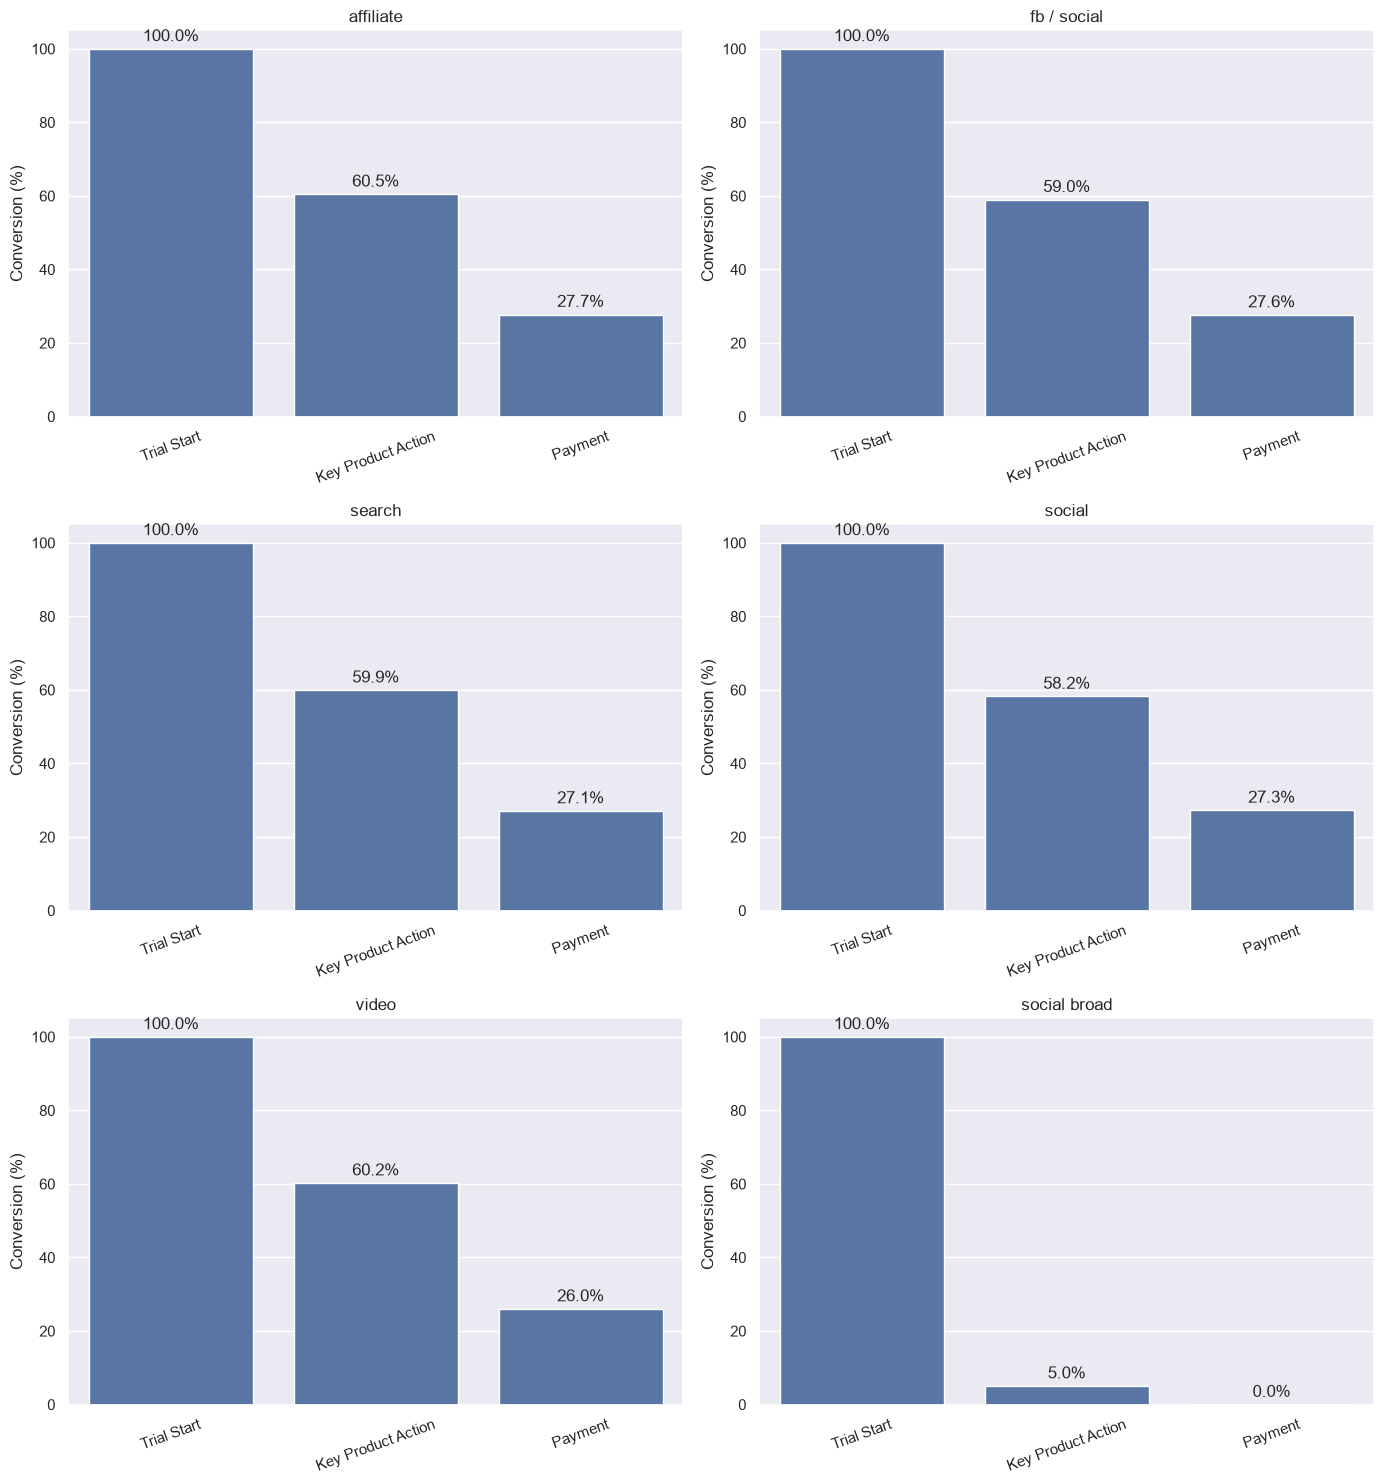

In [263]:
df_funnale_by_channels = pd.read_sql(text("""
WITH params AS (
    SELECT 'month'::text AS date_grain
),
landing_visit AS (
    SELECT
        date_trunc(p.date_grain, e.event_time) AS period,
        e.user_id,
        MIN(e.event_time) AS landing_time
    FROM events e
    CROSS JOIN params p
    WHERE e.event_name = 'landing_visit'
    GROUP BY 1, 2
),
registration AS (
    SELECT
        l.period,
        l.user_id,
        MIN(e.event_time) AS registration_time
    FROM landing_visit l
    JOIN events e
        ON e.user_id = l.user_id
       AND e.event_name = 'registration'
       AND e.event_time >= l.landing_time
    GROUP BY 1, 2
),
trial_start AS (
    SELECT
        r.period,
        r.user_id,
        MIN(e.event_time) AS trial_time
    FROM registration r
    JOIN events e
        ON e.user_id = r.user_id
       AND e.event_name = 'trial_start'
       AND e.event_time >= r.registration_time
    GROUP BY 1, 2
),
key_product_action AS (
    SELECT
        t.period,
        t.user_id,
        MIN(e.event_time) AS action_time
    FROM trial_start t
    JOIN events e
        ON e.user_id = t.user_id
       AND e.event_name = 'key_product_action'
       AND e.event_time >= t.trial_time
    GROUP BY 1, 2
),
payment_succeeded AS (
    SELECT
        t.period,
        t.user_id,
        MIN(p.payment_time) AS payment_time
    FROM trial_start t
    JOIN payments p
        ON p.user_id = t.user_id
       AND p.payment_status = 'succeeded'
       AND p.payment_time >= t.trial_time
    GROUP BY 1, 2
)
SELECT
    l.period,
    LOWER(u.acquisition_channel) AS channel,
    -- 1.0 AS landing_users,
    -- COUNT(DISTINCT r.user_id)::numeric
    --     / NULLIF(COUNT(DISTINCT l.user_id), 0) AS registration_cr,
    COUNT(DISTINCT t.user_id)::numeric
        / NULLIF(COUNT(DISTINCT r.user_id), 0) AS trial_start_cr,

    COUNT(DISTINCT a.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0) AS key_action_cr,

    COUNT(DISTINCT ps.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0) AS payment_cr

FROM landing_visit l

LEFT JOIN registration r
    ON r.user_id = l.user_id
   AND r.period = l.period

LEFT JOIN trial_start t
    ON t.user_id = l.user_id
   AND t.period = l.period

LEFT JOIN key_product_action a
    ON a.user_id = l.user_id
   AND a.period = l.period

LEFT JOIN payment_succeeded ps
    ON ps.user_id = l.user_id
   AND ps.period = l.period

LEFT JOIN users u
    ON u.user_id = l.user_id

GROUP BY 1, 2
ORDER BY 1, 2
"""), engine)

metrics = [
    'trial_start_cr',
    'key_action_cr',
    'payment_cr'
]

stage_names = [
    'Trial Start',
    'Key Product Action',
    'Payment'
]

channels = df_funnale_by_channels['channel'].unique()

ncols = 2
nrows = math.ceil(len(channels) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 5 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, channel in enumerate(channels):
    df_channel = df_funnale_by_channels[
        df_funnale_by_channels['channel'] == channel
    ]

    funnel = (
        df_channel[metrics]
        .mean()
        .mul(100)
        .reset_index()
    )

    funnel.columns = ['stage', 'conversion']
    funnel['stage'] = stage_names

    sns.barplot(
        data=funnel,
        x='stage',
        y='conversion',
        ax=axes[i]
    )

    axes[i].set_title(channel)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Conversion (%)')
    axes[i].tick_params(axis='x', rotation=20)

    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', padding=3)

for j in range(len(channels), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

fig.savefig(
    IMG_DIR / "channel_funnel.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Deeper analysis: landing page variant efficiency

At the previous stage, I compared funnel conversion by acquisition channel and found that the social broad channel performs much worse than the others.

However, aggregated channel metrics do not explain the differences. Therefore, I decided to study conversion by landing page variant within each channel.

This will help check whether results differ between landing page variants and whether this factor may be related to the low conversion of the channel under study.

During the study of the social broad channel, something unexpected was found:
- for all channels, landing page variant A shows better conversion than variant B.

The difference in conversion for the social broad channel:
- Trial start → Key Action: 70% for variant A, 0% for variant B
- Key Action → Payment: 0% for both

The difference in conversion for the other channels:
- Trial start → Key Action: variant A is 3.5 times better than variant B
- Key Action → Payment: variant A is 3 times better than variant B


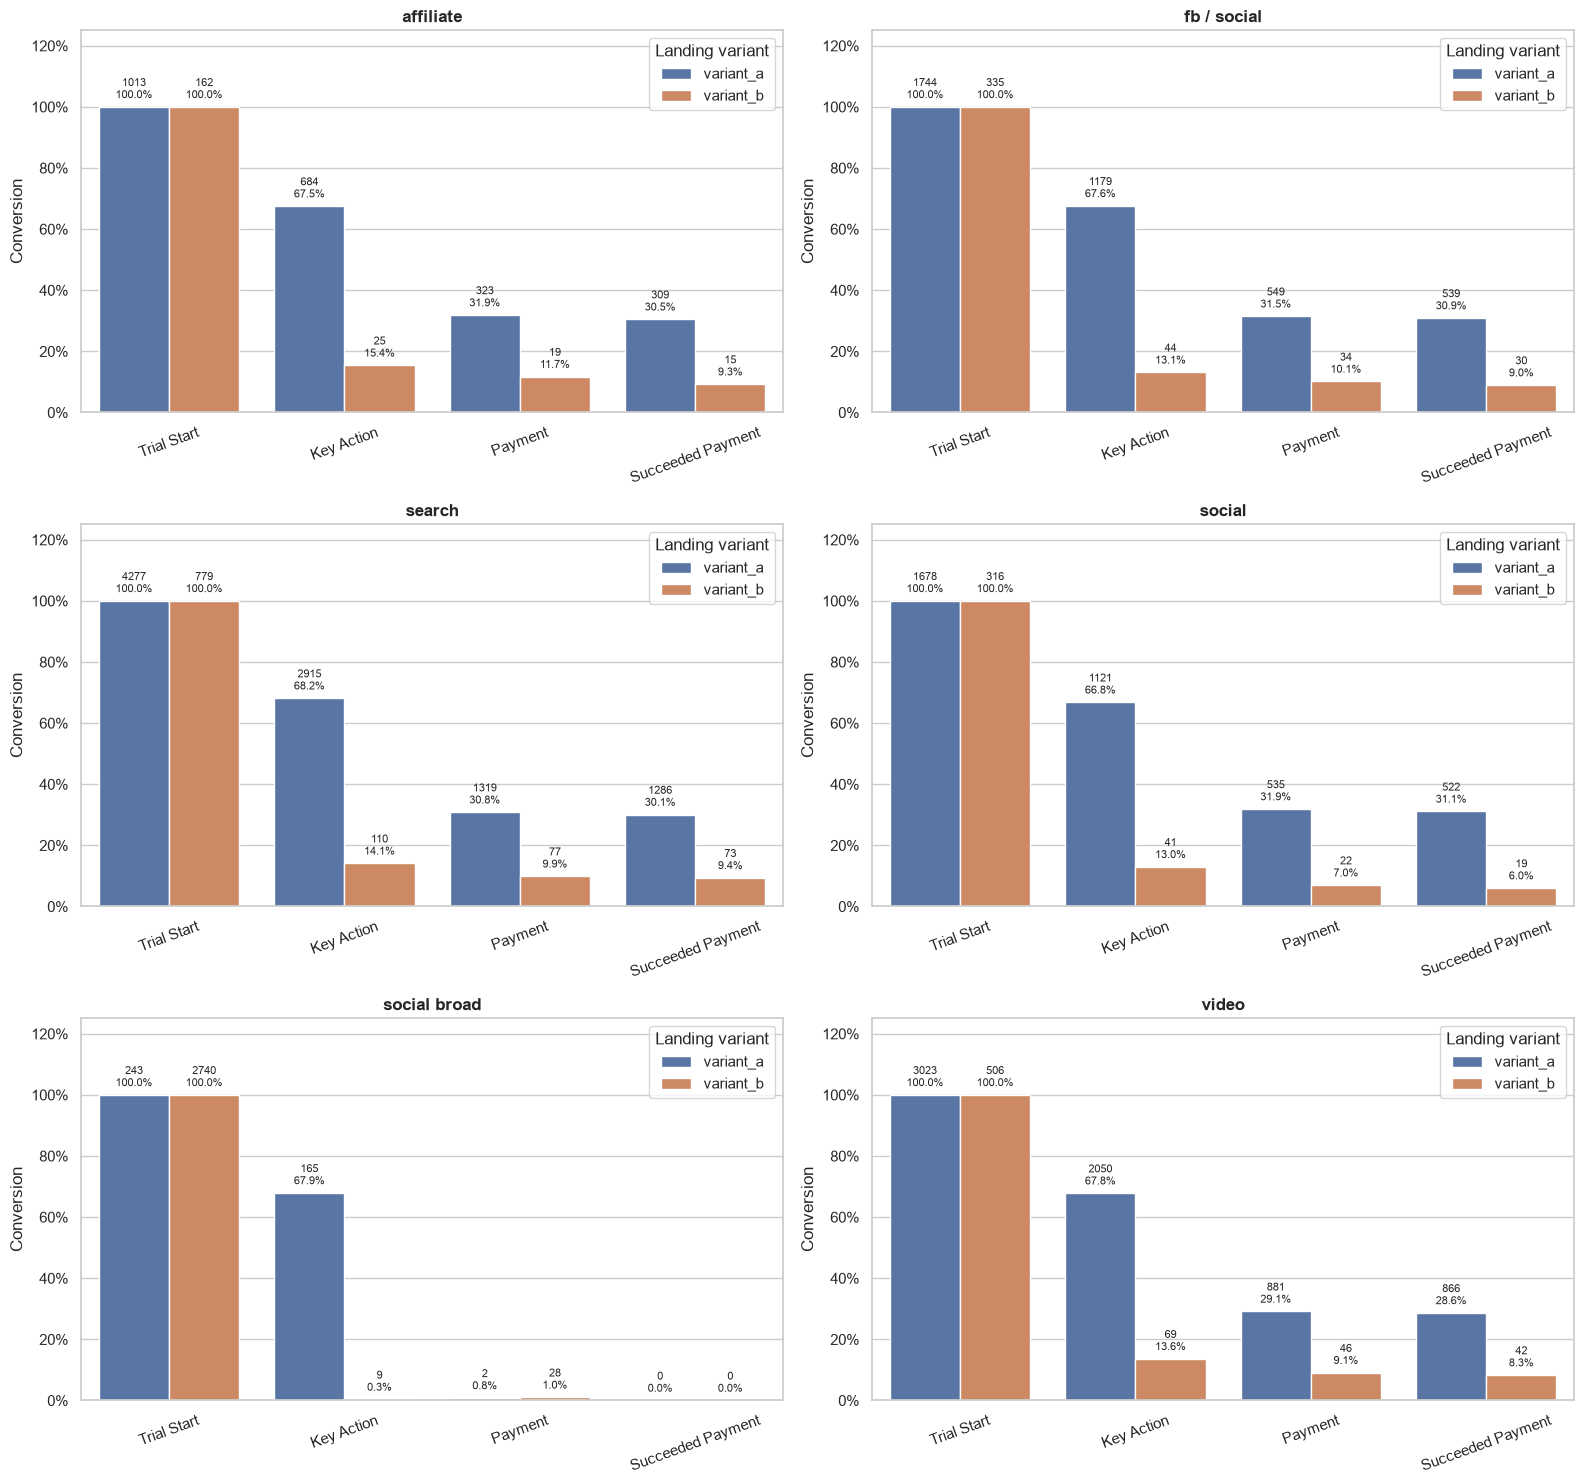

In [264]:

df_funnel_by_landing_var = pd.read_sql(text("""
WITH landing_visit AS (
    SELECT
        e.user_id,
        MIN(e.event_time) AS landing_time
    FROM events e
    WHERE e.event_name = 'landing_visit'
    GROUP BY e.user_id
),

registration AS (
    SELECT
        l.user_id,
        MIN(e.event_time) AS registration_time
    FROM landing_visit l
    JOIN events e
        ON e.user_id = l.user_id
        AND e.event_name = 'registration'
        AND e.event_time >= l.landing_time
    GROUP BY l.user_id
),

trial_start AS (
    SELECT
        r.user_id,
        MIN(e.event_time) AS trial_time
    FROM registration r
    JOIN events e
        ON e.user_id = r.user_id
        AND e.event_name = 'trial_start'
        AND e.event_time >= r.registration_time
    GROUP BY r.user_id
),

key_product_action AS (
    SELECT
        t.user_id,
        MIN(e.event_time) AS action_time
    FROM trial_start t
    JOIN events e
        ON e.user_id = t.user_id
        AND e.event_name = 'key_product_action'
        AND e.event_time >= t.trial_time
    GROUP BY t.user_id
),

payment AS (
    SELECT
        t.user_id,
        MIN(p.payment_time) AS payment_time
    FROM trial_start t
    JOIN payments p
        ON p.user_id = t.user_id
        AND p.payment_time >= t.trial_time
    GROUP BY t.user_id
),

payment_succeeded AS (
    SELECT
        t.user_id,
        MIN(p.payment_time) AS payment_time
    FROM trial_start t
    JOIN payments p
        ON p.user_id = t.user_id
        AND p.payment_status = 'succeeded'
        AND p.payment_time >= t.trial_time
    GROUP BY t.user_id
)

SELECT
    LOWER(u.acquisition_channel) AS acquisition_channel,
    LOWER(u.landing_variant) AS landing_variant,

    -- Абсолютные значения: уникальные пользователи
    COUNT(DISTINCT l.user_id) AS landing_visitors,
    COUNT(DISTINCT r.user_id) AS registrations,
    COUNT(DISTINCT t.user_id) AS trial_starts,
    COUNT(DISTINCT a.user_id) AS key_actions,
    COUNT(DISTINCT p.user_id) AS payments,
    COUNT(DISTINCT ps.user_id) AS succeeded_payments,

    -- Конверсии
    COUNT(DISTINCT t.user_id)::numeric
        / NULLIF(COUNT(DISTINCT r.user_id), 0)
        AS trial_start_cr,

    COUNT(DISTINCT a.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0)
        AS key_action_cr,

    COUNT(DISTINCT p.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0)
        AS payment_cr,

    COUNT(DISTINCT ps.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0)
        AS succeeded_payment_cr

FROM landing_visit l
LEFT JOIN registration r
    ON r.user_id = l.user_id
LEFT JOIN trial_start t
    ON t.user_id = l.user_id
LEFT JOIN key_product_action a
    ON a.user_id = l.user_id
LEFT JOIN payment p
    ON p.user_id = l.user_id
LEFT JOIN payment_succeeded ps
    ON ps.user_id = l.user_id
LEFT JOIN users u
    ON u.user_id = l.user_id

GROUP BY
    LOWER(u.acquisition_channel),
    LOWER(u.landing_variant)

ORDER BY
    acquisition_channel,
    landing_variant;
"""), engine)

stages = [
    ('trial_start_cr', 'trial_starts', 'Trial Start'),
    ('key_action_cr', 'key_actions', 'Key Action'),
    ('payment_cr', 'payments', 'Payment'),
    ('succeeded_payment_cr', 'succeeded_payments', 'Succeeded Payment')
]

stage_order = [stage[2] for stage in stages]
sns.set_theme(style='whitegrid')

channels = sorted(
    df_funnel_by_landing_var['acquisition_channel'].dropna().unique()
)

ncols = 2
nrows = math.ceil(len(channels) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 5 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, channel in enumerate(channels):

    ax = axes[i]

    df_channel = df_funnel_by_landing_var[
        df_funnel_by_landing_var['acquisition_channel'] == channel
    ].copy()

    plot_rows = []

    for _, row in df_channel.iterrows():
        for metric_col, count_col, stage_name in stages:

            plot_rows.append({
                'landing_variant': row['landing_variant'],
                'stage': stage_name,
                'conversion': row[metric_col],
                'users': row[count_col]
            })

    df_plot = pd.DataFrame(plot_rows)

    hue_order = sorted(
        df_plot['landing_variant'].dropna().unique()
    )

    sns.barplot(
        data=df_plot,
        x='stage',
        y='conversion',
        hue='landing_variant',
        order=stage_order,
        hue_order=hue_order,
        errorbar=None,
        ax=ax
    )

    for variant, container in zip(hue_order, ax.containers):

        for stage_idx, bar in enumerate(container):

            height = bar.get_height()

            if pd.isna(height):
                continue

            stage_name = stage_order[stage_idx]

            matching_rows = df_plot[
                (df_plot['landing_variant'] == variant)
                & (df_plot['stage'] == stage_name)
            ]

            if matching_rows.empty:
                continue

            users = matching_rows['users'].iloc[0]

            if pd.isna(users):
                continue

            ax.annotate(
                f'{int(users)}\n{height:.1%}',
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center',
                va='bottom',
                fontsize=8
            )

    ax.set_title(channel, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Conversion')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1.25)
    ax.tick_params(axis='x', rotation=20)

    ax.legend(title='Landing variant')

for j in range(len(channels), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

fig.savefig(
    IMG_DIR / "funnels_by_channels_and_landing_var.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Checking the results

A non-profitable acquisition channel was found. It does not generate profit or paying users at all.

To verify the correctness of the results, the following actions will be taken:
1. Check marketing costs
   - compare profit and CAC
   - review marketing spend by acquisition channel
2. Compare costs
   - compare spend, number of registrations, and net profit with and without the social broad channel


### Checking marketing costs

Users from the social broad channel have no successful orders at all, which means there are no paying users.

Because of this, CAC cannot be calculated for this channel.

In October, spend on social broad was 4.34 times higher than the median spend for the other channels.

This shows that the social broad channel is consuming a large part of the marketing budget.


C:\Temp\ipykernel_2176\3578859499.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


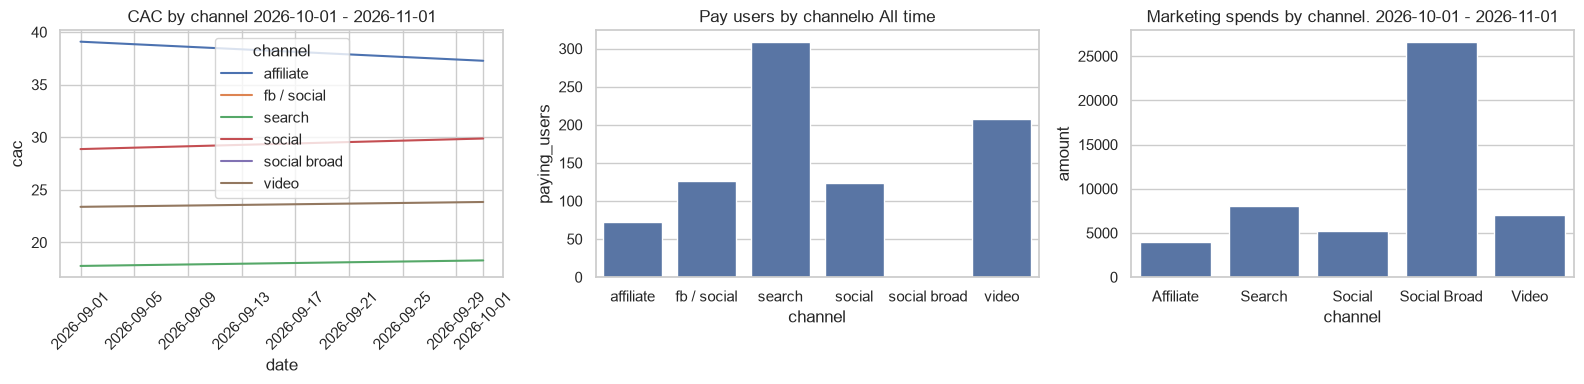

In [265]:
fig, ax = plt.subplots(1,3,figsize=(16,4))

sns.lineplot(df_CAC.query("date >= '2026-09-01' & date < '2026-11-01'"),x='date',y='cac', hue='channel',ax=ax[0])
ax[0].set_title("CAC by channel 2026-10-01 - 2026-11-01")
sns.barplot(df_payment_users_by_channel.sort_values('channel'), x='channel', y='paying_users',ax=ax[1], errorbar=None)
ax[1].set_title("Pay users by channelю All time")
sns.barplot(df_marketing_spend_by_channel.query("date >= '2026-10-01' & date < '2026-11-01'").sort_values('channel'), x='channel', y='amount',ax=ax[2], errorbar=None)
ax[2].set_title("Marketing spends by channel. 2026-10-01 - 2026-11-01")

ax[0].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.tight_layout()

fig.savefig(
    IMG_DIR / "marketing_cost_check.png",
    dpi=150,
    bbox_inches="tight"
)

fig.show()

### Cost comparison

The following patterns were identified:


In [266]:
df_marketing_spend_without_social_broad = df_marketing_spend_by_channel.query("channel != 'Social Broad'").groupby('date').agg(
    amount = ('amount', 'sum')
).reset_index()
df_marketing_spend_without_social_broad['diff'] = ((df_marketing_spend_without_social_broad['amount'] - df_marketing_spend_without_social_broad['amount'].shift(1)) / df_marketing_spend_without_social_broad['amount'].shift(1)) * 100
df_marketing_spend_without_social_broad.iloc[0,2] = 0

df_profit_by_channels = pd.read_sql(text("""
WITH channels AS (
    SELECT DISTINCT
        LOWER(acquisition_channel) AS channel
    FROM users
),
months AS (
    SELECT generate_series(
        DATE '2026-05-01',
        DATE '2026-10-01',
        INTERVAL '1 month'
    ) AS date
),
revenue AS (
    SELECT
        date_trunc('month', p.payment_time) AS date,
        LOWER(u.acquisition_channel) AS channel,
        SUM(p.amount) AS revenue
    FROM payments p
    JOIN users u ON u.user_id = p.user_id
    WHERE p.payment_status = 'succeeded'
      AND p.payment_time >= DATE '2026-05-01'
      AND p.payment_time < DATE '2026-11-01'
    GROUP BY 1, 2
),
marketing AS (
    SELECT
        date_trunc('month', spend_date) AS date,
        LOWER(channel) AS channel,
        SUM(spend_amount) AS marketing_cost
    FROM marketing_spend
    WHERE spend_date >= DATE '2026-05-01'
      AND spend_date < DATE '2026-11-01'
    GROUP BY 1, 2
)
SELECT
    m.date,
    c.channel,
    COALESCE(r.revenue, 0) AS revenue,
    COALESCE(ms.marketing_cost, 0) AS marketing_cost,
    COALESCE(r.revenue, 0)
        - COALESCE(ms.marketing_cost, 0) AS net_profit
FROM months m
CROSS JOIN channels c
LEFT JOIN revenue r
    ON r.date = m.date
   AND r.channel = c.channel
LEFT JOIN marketing ms
    ON ms.date = m.date
   AND ms.channel = c.channel
ORDER BY 1, 2;
"""), engine)
df_profit_by_channels['date'] = pd.to_datetime(df_profit_by_channels['date'])
df_profit_by_channels_without_social_broad = df_profit_by_channels.query("channel != 'social broad'")

#### Without the social broad channel

Marketing spend grows at the usual rate. New users are also increasing at a similar pace. Profit is growing.


C:\Temp\ipykernel_2176\2147393243.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


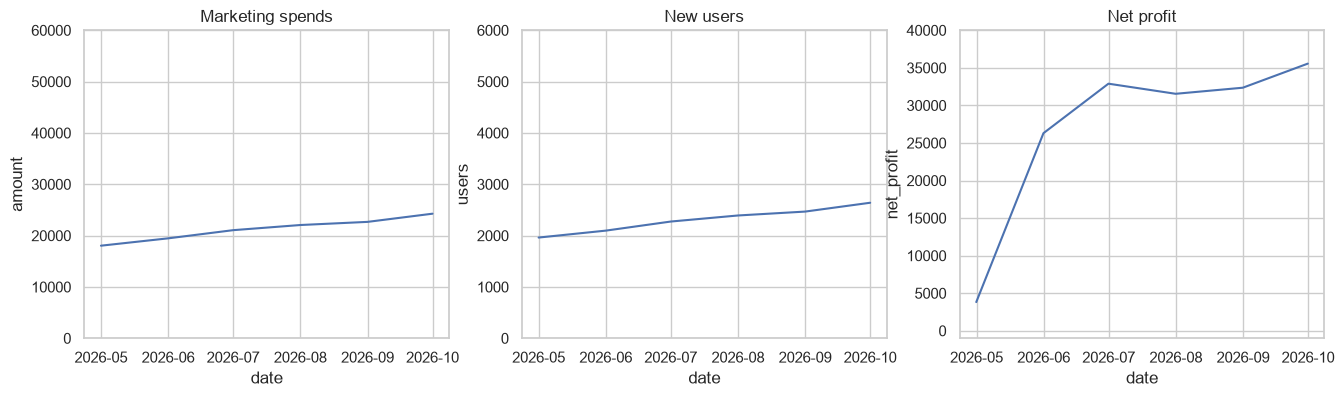

In [267]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.lineplot(df_marketing_spend_without_social_broad, x='date', y='amount',ax=ax[0])
ax[0].set_title("Marketing spends")
ax[0].set_ylim(0,60000)
sns.lineplot(df_new_users.query("channel != 'social broad'").groupby(['date']).agg(users = ('user_count','sum')), x='date', y='users',ax=ax[1])
ax[1].set_title("New users")
ax[1].set_ylim(0,6000)
sns.lineplot(df_profit_by_channels_without_social_broad.groupby('date').agg(net_profit=('net_profit','sum')), x='date', y='net_profit',ax=ax[2])
ax[2].set_title("Net profit")
ax[2].set_ylim(-1000,40000)

fig.savefig(
    IMG_DIR / "last_check_without_bad_channel.png",
    dpi=150,
    bbox_inches="tight"
)

fig.show()

#### With the social broad channel

Marketing spend rose sharply, from 24k to 50k. New users increased by about 50%. At the same time, profit fell from 31k to 9k in the last month.


C:\Temp\ipykernel_2176\3229545787.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


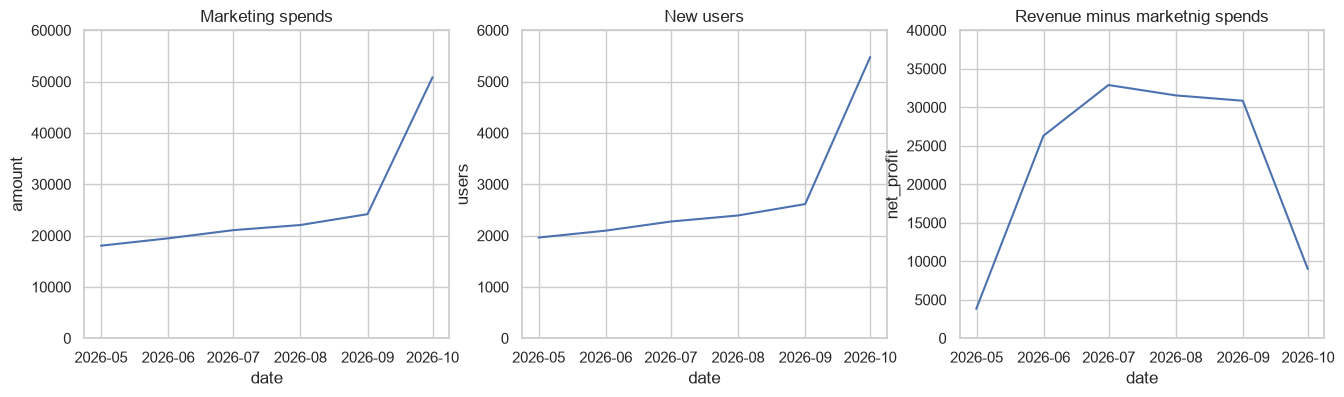

In [268]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.lineplot(df_marketing_spend_by_channel.groupby(['date']).agg(amount = ('amount','sum')), x='date', y='amount',ax=ax[0])
ax[0].set_title("Marketing spends")
ax[0].set_ylim(0,60000)
sns.lineplot(df_new_users.groupby(['date']).agg(users = ('user_count','sum')), x='date', y='users',ax=ax[1])
ax[1].set_title("New users")
ax[1].set_ylim(0,6000)
sns.lineplot(df_profit_by_channels.groupby('date').agg(net_profit=('net_profit','sum')), x='date', y='net_profit',ax=ax[2])
ax[2].set_title("Revenue minus marketnig spends")
ax[2].set_ylim(0,40000)

fig.savefig(
    IMG_DIR / "with_bad_channel.png",
    dpi=150,
    bbox_inches="tight"
)

fig.show()


# Final conclusion

Problem: marketing spend, landing page visits, and registrations increased, but the increase in paying users was much lower than expected.

During the analysis, we found:

- Social broad channel: it was launched on September 27 and did not bring a single paying user during the study period. Marketing spend on this channel is about 3.5 times higher than the median for the other acquisition channels. As a result, in October, revenue after marketing spend was about 9,000 instead of about 35,000 if spend on social broad were excluded.
- Landing page variant B: it shows lower conversion to key product actions and successful payments than variant A.

Recommendations:

1. Pause spending on social broad until the reasons for its low efficiency are clear.
2. Check the quality of the traffic, campaign settings, and the accuracy of payment tracking.
3. Investigate the reasons for the low conversion of landing page B and evaluate whether it can be improved.